# Stage 3c: a real NequIP on CCSD(T) ethanol

`nequip-walkthrough.ipynb` rebuilt NequIP from parts on a toy. Here is the real thing: **nequip 0.19.1**, trained with `nequip-train` on the GTX 1650 Ti, on **sGDML CCSD(T) ethanol**. That's frames from the MD17 ethanol trajectory, with energies and forces recomputed at the coupled-cluster "gold standard" level of quantum chemistry. There are 1000 frames to train on (950 train / 50 validation) and a separate 1000-frame test set.

- **Config:** `nequip-md17/ethanol.yaml`. lmax = 1 with parity, 3 layers, 32 channels, cutoff 4 Å, Bessel radial basis, and per-species avg-neighbour normalization, energy shift and energy scale, all measured from the training split.
- **Rerun:** `.venv/bin/nequip-train -cp $PWD/nequip-md17 -cn ethanol.yaml`
- **Units:** as in the dataset, kcal/mol for energy and kcal/mol/Å for forces. Multiply by 43.36 for meV.

What we check, in order:
1. Did it learn? (learning curves, test parity)
2. Is it symmetric? (the walkthrough's §8 table, now in **float32**, so the exponent lesson from the warm-up comes back)
3. Is it conservative? (work around a closed loop)
4. Does that hold up in a real simulation? (constant-energy MD: no drift)
5. Does lmax 2 buy accuracy on real data? (same config, `l_max=2`)

In [1]:
import warnings
warnings.filterwarnings("ignore")
import time
import numpy as np
import pandas as pd
import torch
import matplotlib
import matplotlib.pyplot as plt
from ase import Atoms, units
from ase.md.verlet import VelocityVerlet
from ase.md.velocitydistribution import MaxwellBoltzmannDistribution, Stationary, ZeroRotation

from nequip.utils.global_state import set_global_state
set_global_state()                       # nequip requires this before building or loading a model in Python
from nequip.model.saved_models.checkpoint import ModelFromCheckpoint
from nequip.integrations.ase import NequIPCalculator
from nequip.data.transforms import ChemicalSpeciesToAtomTypeMapper, NeighborListTransform

RUN = "nequip-md17/outputs/ethanol-lmax1"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
KCAL_TO_EV = 0.0433641                   # 1 kcal/mol in eV
KCAL_TO_MEV = 1000 * KCAL_TO_EV

model = ModelFromCheckpoint(f"{RUN}/best.ckpt")["sole_model"].eval()     # returns a ModuleDict; ours is "sole_model"
print("model dtype:", next(model.parameters()).dtype, "| parameters:", sum(p.numel() for p in model.parameters()),
      "| device:", DEVICE)

def make_calc(energy_units_to_eV=1.0):
    return NequIPCalculator(model, device=DEVICE, energy_units_to_eV=energy_units_to_eV, transforms=[
        ChemicalSpeciesToAtomTypeMapper(model_type_names=["C", "O", "H"],
                                        chemical_species_to_atom_type_map={"C": "C", "O": "O", "H": "H"}),
        NeighborListTransform(r_max=4.0)])
calc = make_calc()                        # native units: kcal/mol, kcal/mol/Å

test = np.load("nequip-md17/data/ethanol_ccsd_t-test.npz")
Z, R_test, E_test, F_test = test["z"], test["R"], test["E"].ravel(), test["F"]
print("test set:", R_test.shape[0], "frames of", "".join({6: "C", 8: "O", 1: "H"}[z] for z in Z),
      f"| energies around {E_test.mean():.0f} kcal/mol, spread {E_test.std():.2f} | force RMS {np.sqrt((F_test**2).mean()):.1f}")

def eval_frame(pos, c=calc):
    at = Atoms(numbers=Z, positions=pos); at.calc = c
    return at.get_potential_energy(), at.get_forces()

model dtype: torch.float32 | parameters: 204416 | device: cuda
test set: 1000 frames of CCOHHHHHH | energies around -97085 kcal/mol, spread 4.73 | force RMS 27.5


In [2]:
# ---- palette and a molecule-drawing helper (same style as the other stage-3 notebooks) ----
GOOD, CRITICAL, INK, MUTED, BAND, BG = "#0ca30c", "#d03b3b", "#0b0b0b", "#52514e", "#f0efec", "#fcfcfb"
BLUE, ORANGE, PURPLE = "#2a6fdb", "#e08a1e", "#7b4fc9"
plt.rcParams.update({"figure.facecolor": BG, "axes.facecolor": BG, "savefig.facecolor": BG,
                     "axes.edgecolor": MUTED, "axes.labelcolor": MUTED, "text.color": INK,
                     "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 9,
                     "axes.titlesize": 10, "axes.titlelocation": "left", "figure.dpi": 100,
                     "axes.spines.top": False, "axes.spines.right": False})
ATOM_STYLE = {6: ("#4b5563", 230), 8: ("#d03b3b", 230), 1: ("#c7ccd1", 90)}

def ax3d(fig, *spec, title="", lim=2.2, center=(0, 0, 0), elev=20, azim=-60):
    ax = fig.add_subplot(*spec, projection="3d")
    c = center
    ax.set_xlim(c[0] - lim, c[0] + lim); ax.set_ylim(c[1] - lim, c[1] + lim); ax.set_zlim(c[2] - lim, c[2] + lim)
    ax.set_box_aspect((1, 1, 1)); ax.view_init(elev, azim)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])
    for a in (ax.xaxis, ax.yaxis, ax.zaxis):
        a.pane.fill = False; a.pane.set_edgecolor(BAND)
    ax.set_title(title, loc="left", fontsize=9.5)
    return ax

def draw_mol(ax, pos, alpha=1.0):
    d = np.linalg.norm(pos[:, None] - pos[None], axis=-1)
    for i in range(len(pos)):
        for j in range(i + 1, len(pos)):
            if d[i, j] < 1.7:
                ax.plot(*zip(pos[i], pos[j]), color=MUTED, lw=1.6, alpha=0.5 * alpha)
    for i, z in enumerate(Z):
        col, s = ATOM_STYLE[z]
        ax.scatter(*pos[i], s=s, color=col, alpha=alpha, depthshade=False, edgecolor="white", linewidth=0.5)

def draw_forces(ax, pos, F, color, scale, lw=2.0, alpha=1.0):
    ax.quiver(*pos.T, *(F * scale).T, color=color, lw=lw, alpha=alpha, arrow_length_ratio=0.25)

## 1. Did it learn? Learning curves

Lightning logged validation metrics every epoch (`lightning_logs/version_0/metrics.csv`). The learning rate drops by ×0.6 whenever validation stalls for 10 epochs, and training stops early after 40 epochs without improvement.

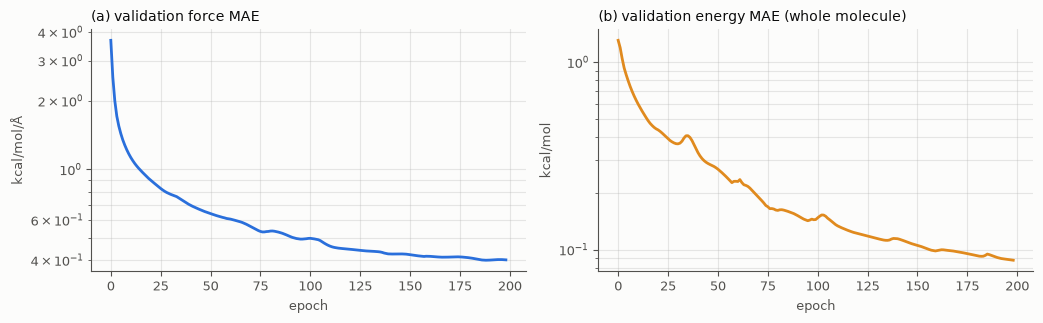

199 epochs; best epoch 198: force MAE 0.401 kcal/mol/Å, energy MAE 0.088 kcal/mol


In [3]:
log = pd.read_csv(f"{RUN}/lightning_logs/version_0/metrics.csv")
val = log.dropna(subset=["val0_epoch/forces_mae"]).groupby("epoch").last()

fig, axs = plt.subplots(1, 2, figsize=(10.5, 3.3))
axs[0].semilogy(val.index, val["val0_epoch/forces_mae"], color=BLUE, lw=2)
axs[0].set_title("(a) validation force MAE"); axs[0].set_ylabel("kcal/mol/Å"); axs[0].set_xlabel("epoch")
axs[1].semilogy(val.index, val["val0_epoch/total_energy_mae"], color=ORANGE, lw=2)
axs[1].set_title("(b) validation energy MAE (whole molecule)"); axs[1].set_ylabel("kcal/mol"); axs[1].set_xlabel("epoch")
for ax in axs:
    ax.grid(alpha=0.3, which="both")
plt.tight_layout(); plt.show()
best = val["val0_epoch/weighted_sum"].idxmin()
print(f"{len(val)} epochs; best epoch {best}: force MAE {val.loc[best, 'val0_epoch/forces_mae']:.3f} kcal/mol/Å,"
      f" energy MAE {val.loc[best, 'val0_epoch/total_energy_mae']:.3f} kcal/mol")

## 2. Test set: 1000 frames the model never saw

**The picture:** for every test frame, the model's prediction against CCSD(T). Perfect predictions sit on the diagonal. Energies are plotted relative to the test-set mean, because the absolute values (about −97,000 kcal/mol) are the energy of all electrons and dwarf the variation we care about. That's exactly why NequIP has the per-species **shift**.

evaluated 1000 frames in 38.7 s


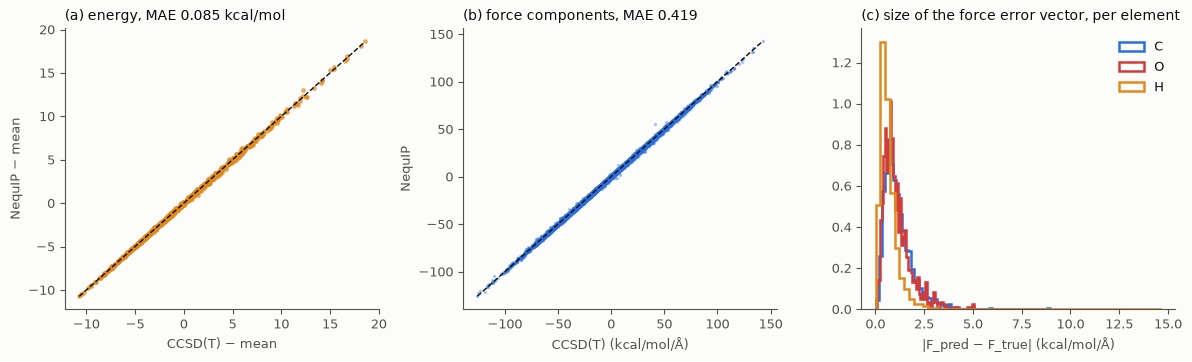

energy MAE 0.085 kcal/mol = 3.7 meV   (predict-the-mean baseline: 3.72 kcal/mol)
force  MAE 0.419 kcal/mol/Å = 18.2 meV/Å   (predict-zero baseline: 20.8 kcal/mol/Å)


In [4]:
t0 = time.time()
E_pred, F_pred = zip(*[eval_frame(p) for p in R_test])
E_pred, F_pred = np.array(E_pred), np.array(F_pred)
print(f"evaluated {len(E_pred)} frames in {time.time() - t0:.1f} s")

e_mae, f_mae = np.abs(E_pred - E_test).mean(), np.abs(F_pred - F_test).mean()
f_base = np.abs(F_test).mean()                       # "predict zero force" baseline
e_base = np.abs(E_test - E_test.mean()).mean()       # "predict the mean energy" baseline

fig, axs = plt.subplots(1, 3, figsize=(12, 3.7))
e0 = E_test.mean()
axs[0].scatter(E_test - e0, E_pred - e0, s=6, color=ORANGE, alpha=0.6)
lim = [min(E_test - e0), max(E_test - e0)]
axs[0].plot(lim, lim, color=INK, lw=1, ls="--")
axs[0].set_title(f"(a) energy, MAE {e_mae:.3f} kcal/mol"); axs[0].set_xlabel("CCSD(T) − mean"); axs[0].set_ylabel("NequIP − mean")
axs[1].scatter(F_test.ravel(), F_pred.ravel(), s=2, color=BLUE, alpha=0.3)
lim = [F_test.min(), F_test.max()]
axs[1].plot(lim, lim, color=INK, lw=1, ls="--")
axs[1].set_title(f"(b) force components, MAE {f_mae:.3f}"); axs[1].set_xlabel("CCSD(T) (kcal/mol/Å)"); axs[1].set_ylabel("NequIP")
err = np.linalg.norm(F_pred - F_test, axis=-1)
for z, lab, col in [(6, "C", BLUE), (8, "O", CRITICAL), (1, "H", ORANGE)]:
    axs[2].hist(err[:, Z == z].ravel(), bins=60, histtype="step", lw=1.8, color=col, density=True, label=lab)
axs[2].set_title("(c) size of the force error vector, per element"); axs[2].set_xlabel("|F_pred − F_true| (kcal/mol/Å)")
axs[2].legend(frameon=False)
plt.tight_layout(); plt.show()

print(f"energy MAE {e_mae:.3f} kcal/mol = {e_mae * KCAL_TO_MEV:.1f} meV   (predict-the-mean baseline: {e_base:.2f} kcal/mol)")
print(f"force  MAE {f_mae:.3f} kcal/mol/Å = {f_mae * KCAL_TO_MEV:.1f} meV/Å   (predict-zero baseline: {f_base:.1f} kcal/mol/Å)")

**How to read the numbers.** Compare each MAE with its baseline: the force error is a small fraction of the typical force. A widely used rule of thumb for "chemical accuracy" is 1 kcal/mol in energy. Our energy error is the whole-molecule error, so for a 9-atom molecule the per-atom error is ~9× smaller still. Ours is a small model (lmax 1, 32 channels) trained for about four hours on a laptop GPU. The NequIP paper (arXiv:2101.03164) reports results on these same CCSD(T) sets with bigger models and much longer training, so treat its table as the ceiling to compare against.

The per-element histogram (c) is worth a glance. You might guess hydrogens, the lightest and fastest atoms, are the hardest. They aren't: the heavy atoms carry the largest forces (mean force component C ≈ 31, O ≈ 25, H ≈ 17 kcal/mol/Å), and their errors are the widest too. The error follows the size of the force.

### One frame, as a picture

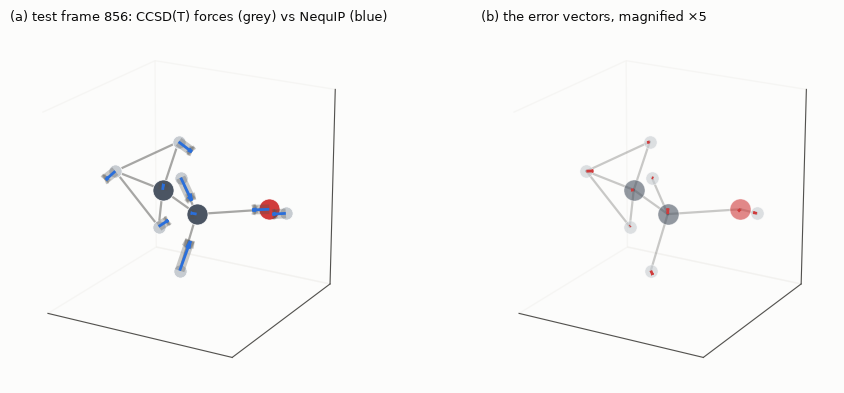

frame 856: energy +18.55 kcal/mol from the mean, model error +0.118


In [5]:
k = int(np.argmax(np.abs(E_test - E_test.mean())))     # a far-from-average frame: a harder case
pos = R_test[k] - R_test[k].mean(0)
s = 0.6 / np.abs(F_test[k]).max()
fig = plt.figure(figsize=(10, 4))
ax = ax3d(fig, 1, 2, 1, title=f"(a) test frame {k}: CCSD(T) forces (grey) vs NequIP (blue)")
draw_mol(ax, pos); draw_forces(ax, pos, F_test[k], MUTED, s, lw=7, alpha=0.3); draw_forces(ax, pos, F_pred[k], BLUE, s)
ax = ax3d(fig, 1, 2, 2, title="(b) the error vectors, magnified ×5", )
draw_mol(ax, pos, alpha=0.6); draw_forces(ax, pos, F_pred[k] - F_test[k], CRITICAL, 5 * s)
plt.tight_layout(); plt.show()
print(f"frame {k}: energy {E_test[k] - E_test.mean():+.2f} kcal/mol from the mean, model error {E_pred[k] - E_test[k]:+.3f}")

## 3. Is it symmetric? The §8 table, in float32

The same checks as the walkthrough's §8, one per symmetry. One difference: this model runs in **float32** (`model_dtype: float32` in the config, as is standard for training speed). So the numbers to expect are not 1e-15:
- float32 machine epsilon ≈ 1.2e-7
- forces here are ~10–100 kcal/mol/Å, so round-off lands around 1e-6 to 1e-4
- a real bug would be of order the forces themselves

This is warm-up question 3 again: read the **exponent relative to the scale**, and remember round-off grows with the precision you run in.

In [6]:
p0 = R_test[0].astype(np.float64)
E0, F0 = eval_frame(p0)
Q, _ = np.linalg.qr(np.random.default_rng(0).normal(size=(3, 3)))
Rm = Q * np.sign(np.linalg.det(Q))                                 # a proper rotation (det = +1)
t = np.array([3.0, -7.0, 11.0])
Et, Ft = eval_frame(p0 + t)
Er, Fr = eval_frame(p0 @ Rm.T)
Ei, Fi = eval_frame(-p0)
torque = np.cross(p0 - p0.mean(0), F0).sum(0)

scale_F = np.abs(F0).max()
rows = [("translation", "energy unchanged", abs(Et - E0)),
        ("translation", "ΣF = 0", np.abs(F0.sum(0)).max()),
        ("rotation", "energy unchanged", abs(Er - E0)),
        ("rotation", "forces turn with the molecule", np.abs(Fr - F0 @ Rm.T).max()),
        ("rotation", "Σ r × F = 0 (net torque)", np.abs(torque).max()),
        ("inversion", "energy unchanged", abs(Ei - E0)),
        ("inversion", "forces flip (true vectors)", np.abs(Fi + F0).max())]
print(f"force scale {scale_F:.1f} kcal/mol/Å · float32 eps {np.finfo(np.float32).eps:.1e} → round-off ≈ {scale_F * np.finfo(np.float32).eps:.0e} and up\n")
for sym, prop, e in rows:
    print(f"{sym:12s} {prop:32s} {e:.1e}")

force scale 32.1 kcal/mol/Å · float32 eps 1.2e-07 → round-off ≈ 4e-06 and up

translation  energy unchanged                 1.6e-07
translation  ΣF = 0                           6.2e-15
rotation     energy unchanged                 1.6e-06
rotation     forces turn with the molecule    9.6e-06
rotation     Σ r × F = 0 (net torque)         1.4e-06
inversion    energy unchanged                 6.1e-07
inversion    forces flip (true vectors)       7.8e-06


Every force and energy row sits at roughly eps × scale, give or take an order of magnitude for accumulated arithmetic. That's float32 round-off, still many orders of magnitude below the forces.

Two rows are worth a second look:
- **ΣF comes out far smaller than the rest.** The model's energy depends on positions only through edge vectors pos[j] − pos[i]. So each edge's gradient is added to its two atoms with **opposite signs**, and the sum over atoms cancels almost exactly. That's the warm-up's translation argument, showing up in the arithmetic itself.
- **The energy errors are tiny even though the energy is ~97,000.** A float32 number that large can only resolve ~0.01, so nequip evidently doesn't add the big per-species shift in float32. I measured this rather than read it in the source.

## 4. Is it conservative? Walk an atom around a closed loop

**The picture to keep** (warm-up question 4): drag one atom around a small closed loop and add up the work the force does. If F = −∂E/∂x, the work around *any* closed loop is exactly zero: you're back at the same energy. A force field without an energy behind it, like a direct force head, can leave net work after each loop, and that's what pumps energy into an MD run.

We drag the hydroxyl hydrogen around a 0.15 Å circle, with everything else frozen. For contrast, we add a small *made-up* swirl to the model's force, the kind of non-conservative error a direct force head could have, and repeat.

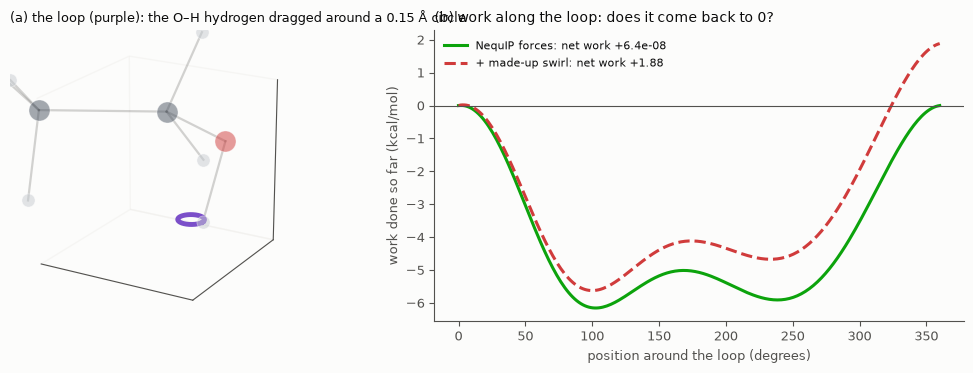

largest work excursion along the loop 6.153 kcal/mol; net after one loop +6.4e-08 kcal/mol


In [7]:
h_oh = int(np.where(Z == 1)[0][np.argmin(np.linalg.norm(R_test[0][Z == 1] - R_test[0][Z == 8][0], axis=1))])  # H bonded to O
base = R_test[0].astype(np.float64).copy()
n_pts, radius = 240, 0.15
th = np.linspace(0, 2 * np.pi, n_pts + 1)
u, v = np.eye(3)[0], np.eye(3)[1]
centre = base[h_oh]
path = centre + radius * (np.cos(th)[:, None] * u + np.sin(th)[:, None] * v) - radius * u   # starts and ends at the real position

F_path = []
for x in path:
    p = base.copy(); p[h_oh] = x
    F_path.append(eval_frame(p)[1][h_oh])
F_path = np.array(F_path)
swirl = 2.0 * np.cross(np.eye(3)[2], path - (centre - radius * u)) / radius     # made-up curl field, size ~2 kcal/mol/Å

def cumulative_work(F, path):              # W = ∫ F · dx, trapezoid rule
    dx = np.diff(path, axis=0)
    return np.concatenate([[0], np.cumsum(0.5 * ((F[1:] + F[:-1]) * dx).sum(1))])

W_model, W_swirl = cumulative_work(F_path, path), cumulative_work(F_path + swirl, path)

fig = plt.figure(figsize=(11, 3.8))
ax = ax3d(fig, 1, 2, 1, title="(a) the loop (purple): the O–H hydrogen dragged around a 0.15 Å circle",
          lim=1.0, center=0.5 * (base.mean(0) + centre))
draw_mol(ax, base, alpha=0.5); ax.plot(*path.T, color=PURPLE, lw=3.5)
ax2 = fig.add_subplot(1, 2, 2)
ax2.plot(np.degrees(th), W_model, color=GOOD, lw=2.2, label=f"NequIP forces: net work {W_model[-1]:+.1e}")
ax2.plot(np.degrees(th), W_swirl, color=CRITICAL, lw=2.2, ls="--", label=f"+ made-up swirl: net work {W_swirl[-1]:+.2f}")
ax2.axhline(0, color=MUTED, lw=0.8)
ax2.set_xlabel("position around the loop (degrees)"); ax2.set_ylabel("work done so far (kcal/mol)")
ax2.set_title("(b) work along the loop: does it come back to 0?"); ax2.legend(frameon=False, fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()
print(f"largest work excursion along the loop {np.abs(W_model).max():.3f} kcal/mol; net after one loop {W_model[-1]:+.1e} kcal/mol")

**Reading it.** Along the way, the work rises and falls by a sizeable amount as the hydrogen climbs and descends the energy landscape. But the green curve **returns to zero** when the loop closes, up to the trapezoid-rule and float32 error. The red curve shows what a non-conservative error of only ~2 kcal/mol/Å does: it ends the loop with energy gained from nowhere, and an MD run would collect that on every near-loop the atoms trace.

## 5. Does it hold up in a real simulation? Constant-energy MD

The real test of everything above. We run **NVE molecular dynamics**: no thermostat, Newton's equations only, starting from a test geometry with random 300 K velocities. If forces are conservative and smooth, the total energy E_pot + E_kin should **fluctuate but not drift**.

To show where the fluctuation comes from, we run the same 0.5 ps twice, with timesteps of 0.5 fs and 0.25 fs.

two NVE runs of 0.5 ps in 127 s


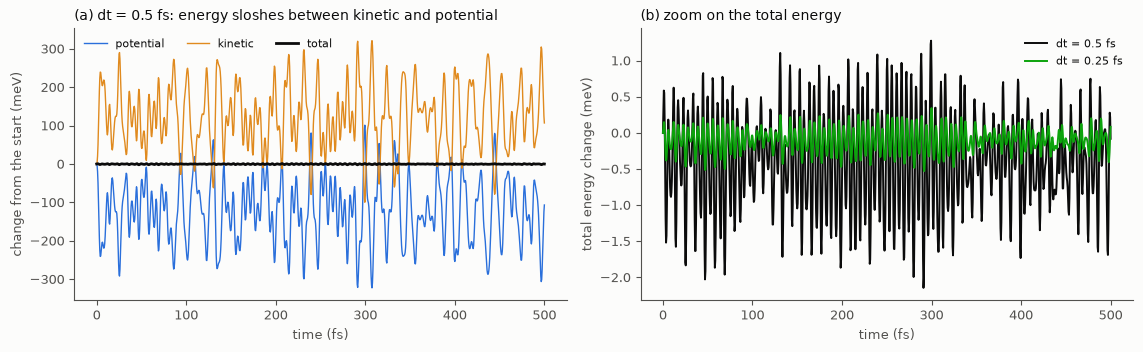

dt  0.5 fs: kinetic energy swings  420.7 meV | total energy: fluctuation (std) 0.673 meV, drift +0.00 meV/ps | mean T 316 K
dt 0.25 fs: kinetic energy swings  439.5 meV | total energy: fluctuation (std) 0.165 meV, drift +0.00 meV/ps | mean T 317 K


In [8]:
def run_nve(dt_fs, total_fs=500, seed=0, start=0):
    at = Atoms(numbers=Z, positions=R_test[start].astype(np.float64))
    at.calc = make_calc(energy_units_to_eV=KCAL_TO_EV)          # ASE works in eV, so convert
    MaxwellBoltzmannDistribution(at, temperature_K=300, rng=np.random.default_rng(seed))
    Stationary(at); ZeroRotation(at)                             # no net drift or spin
    dyn = VelocityVerlet(at, timestep=dt_fs * units.fs)
    rec = []
    def log():
        rec.append((at.get_potential_energy(), at.get_kinetic_energy(), at.get_temperature()))
    dyn.attach(log, interval=1)
    dyn.run(int(total_fs / dt_fs))
    rec = np.array(rec) * np.array([1000, 1000, 1])                  # eV -> meV for energies
    return np.arange(len(rec)) * dt_fs, rec

t0 = time.time()
runs = {dt: run_nve(dt) for dt in [0.5, 0.25]}
print(f"two NVE runs of 0.5 ps in {time.time() - t0:.0f} s")

fig, axs = plt.subplots(1, 2, figsize=(11.5, 3.6))
tt, rec = runs[0.5]
Etot = rec[:, 0] + rec[:, 1]
axs[0].plot(tt, rec[:, 0] - rec[0, 0], color=BLUE, lw=1, label="potential")
axs[0].plot(tt, rec[:, 1] - rec[0, 1], color=ORANGE, lw=1, label="kinetic")
axs[0].plot(tt, Etot - Etot[0], color=INK, lw=2, label="total")
axs[0].set_xlabel("time (fs)"); axs[0].set_ylabel("change from the start (meV)")
axs[0].set_title("(a) dt = 0.5 fs: energy sloshes between kinetic and potential"); axs[0].legend(frameon=False, fontsize=8, ncol=3)
for dt, col in [(0.5, INK), (0.25, GOOD)]:
    tt, rec = runs[dt]
    Etot = rec[:, 0] + rec[:, 1]
    axs[1].plot(tt, Etot - Etot[0], color=col, lw=1.4, label=f"dt = {dt} fs")
axs[1].set_xlabel("time (fs)"); axs[1].set_ylabel("total energy change (meV)")
axs[1].set_title("(b) zoom on the total energy"); axs[1].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

for dt in runs:
    tt, rec = runs[dt]
    Etot = rec[:, 0] + rec[:, 1]
    slope = np.polyfit(tt, Etot, 1)[0] * 1000                   # meV per ps
    print(f"dt {dt:4} fs: kinetic energy swings {np.ptp(rec[:, 1]):6.1f} meV | total energy: fluctuation (std) {Etot.std():.3f} meV,"
          f" drift {slope:+.2f} meV/ps | mean T {rec[:, 2].mean():.0f} K")

**Reading it:**
- **Panel (a):** kinetic and potential energy each swing by hundreds of meV as the molecule vibrates, mirror images of each other. The total (black) is nearly flat.
- **Panel (b):** zoom in on the total. It **fluctuates** but doesn't trend away, and the fitted drift is tiny next to the swings in (a).

Halving the timestep shrinks the fluctuation by roughly 4×. That's the signature of the Verlet integrator's own error, which scales like dt². It isn't the model: a conservative force field plus a symplectic integrator gives bounded fluctuations with no systematic drift. Bounded fluctuation, no drift, is what conservative forces buy you in a long simulation.

Caveat: 0.5 ps on one molecule is a short test. Production checks run nanoseconds and also watch for the model wandering into geometries it never saw in training. That's a separate failure mode from drift, and it's where active learning comes in for your SiO₂ work.

## 6. lmax 1 vs lmax 2 on real data

The walkthrough's toy made lmax look like an on/off switch: the lmax-1 model **could not see** the symmetric squash of SiO₄, however long it trained. Real ethanol should be gentler. Bond angles already reach an lmax-1 model as dot products of two vectors (the 1 ⊗ 1 → 0 path), and three layers compound that. What lmax 2 adds is a 5-component **shape** feature per channel: how stretched or flattened the neighbour cloud is, not only which way it leans. So expect a difference of degree, not of kind.

The rerun changes one thing on the command line, `training_module.model.l_max=2`. The data split, seed, channels, layers, cutoff and training schedule are all identical, so whatever differs comes from lmax.

parameters: lmax 1 204,416 | lmax 2 351,872 (1.72×)


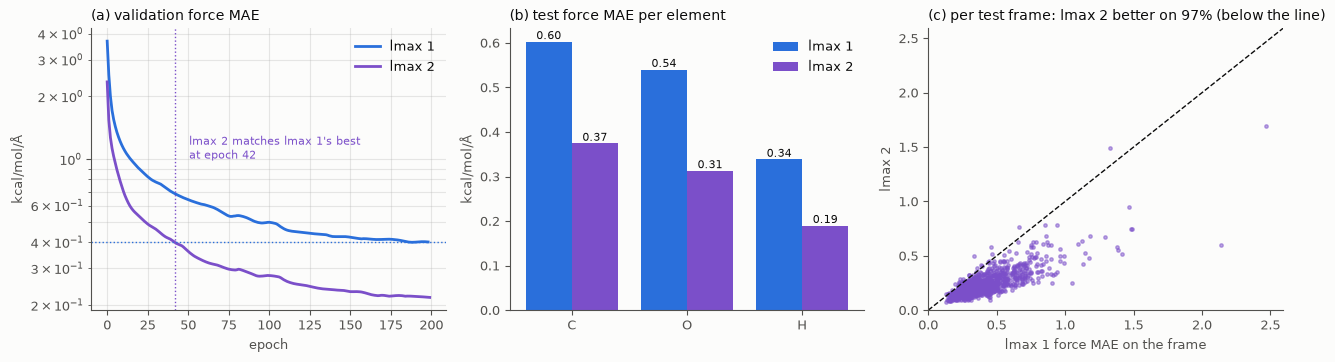

                              lmax 1   lmax 2
parameters                   204,416  351,872
epochs trained                   199      200
best epoch                       198      199
test energy MAE (kcal/mol)     0.085    0.049
test force MAE (kcal/mol/Å)    0.419    0.244
inference (ms/frame)              42       63


In [9]:
RUN2 = "nequip-md17/outputs/ethanol-lmax2"
model2 = ModelFromCheckpoint(f"{RUN2}/best.ckpt")["sole_model"].eval()
calc2 = NequIPCalculator(model2, device=DEVICE, transforms=[
    ChemicalSpeciesToAtomTypeMapper(model_type_names=["C", "O", "H"],
                                    chemical_species_to_atom_type_map={"C": "C", "O": "O", "H": "H"}),
    NeighborListTransform(r_max=4.0)])
n1, n2 = (sum(p.numel() for p in m.parameters()) for m in (model, model2))
print(f"parameters: lmax 1 {n1:,} | lmax 2 {n2:,} ({n2 / n1:.2f}×)")

E_pred2, F_pred2 = map(np.array, zip(*[eval_frame(p, calc2) for p in R_test]))

def ms_per_frame(c, n=200):                 # inference speed, same 200 frames for both
    t0 = time.time()
    for p in R_test[:n]:
        eval_frame(p, c)
    return 1000 * (time.time() - t0) / n

log2 = pd.read_csv(f"{RUN2}/lightning_logs/version_0/metrics.csv")
val2 = log2.dropna(subset=["val0_epoch/forces_mae"]).groupby("epoch").last()
best2 = val2["val0_epoch/weighted_sum"].idxmin()
target = val.loc[best, "val0_epoch/forces_mae"]                       # lmax 1's best validation force MAE
catch_up = val2.index[val2["val0_epoch/forces_mae"] <= target]
catch_up = int(catch_up[0]) if len(catch_up) else None

fig, axs = plt.subplots(1, 3, figsize=(13, 3.7))
axs[0].semilogy(val.index, val["val0_epoch/forces_mae"], color=BLUE, lw=2, label="lmax 1")
axs[0].semilogy(val2.index, val2["val0_epoch/forces_mae"], color=PURPLE, lw=2, label="lmax 2")
axs[0].axhline(target, color=BLUE, lw=1, ls=":")
if catch_up is not None:
    axs[0].axvline(catch_up, color=PURPLE, lw=1, ls=":")
    axs[0].annotate(f"lmax 2 matches lmax 1's best\nat epoch {catch_up}", (catch_up, target), xytext=(10, 60),
                    textcoords="offset points", fontsize=8, color=PURPLE)
axs[0].set_title("(a) validation force MAE"); axs[0].set_xlabel("epoch"); axs[0].set_ylabel("kcal/mol/Å")
axs[0].legend(frameon=False); axs[0].grid(alpha=0.3, which="both")

els = [(6, "C"), (8, "O"), (1, "H")]
mae_el = lambda F: [np.abs(F[:, Z == z] - F_test[:, Z == z]).mean() for z, _ in els]
x = np.arange(len(els))
b1 = axs[1].bar(x - 0.2, mae_el(F_pred), 0.4, color=BLUE, label="lmax 1")
b2 = axs[1].bar(x + 0.2, mae_el(F_pred2), 0.4, color=PURPLE, label="lmax 2")
axs[1].bar_label(b1, fmt="%.2f", fontsize=8); axs[1].bar_label(b2, fmt="%.2f", fontsize=8)
axs[1].set_xticks(x, [s for _, s in els]); axs[1].set_ylabel("kcal/mol/Å")
axs[1].set_title("(b) test force MAE per element"); axs[1].legend(frameon=False)

fe1 = np.abs(F_pred - F_test).mean(axis=(1, 2)); fe2 = np.abs(F_pred2 - F_test).mean(axis=(1, 2))
axs[2].scatter(fe1, fe2, s=6, color=PURPLE, alpha=0.5)
lim = [0, max(fe1.max(), fe2.max()) * 1.05]
axs[2].plot(lim, lim, color=INK, lw=1, ls="--"); axs[2].set_xlim(lim); axs[2].set_ylim(lim)
axs[2].set_title(f"(c) per test frame: lmax 2 better on {(fe2 < fe1).mean():.0%} (below the line)")
axs[2].set_xlabel("lmax 1 force MAE on the frame"); axs[2].set_ylabel("lmax 2")
plt.tight_layout(); plt.show()

t1, t2 = ms_per_frame(calc), ms_per_frame(calc2)
col = lambda n, v, b, E, F, t: [f"{n:,}", len(v), b, f"{np.abs(E - E_test).mean():.3f}",
                                f"{np.abs(F - F_test).mean():.3f}", f"{t:.0f}"]
summary = pd.DataFrame({"lmax 1": col(n1, val, best, E_pred, F_pred, t1),
                        "lmax 2": col(n2, val2, best2, E_pred2, F_pred2, t2)},
    index=["parameters", "epochs trained", "best epoch", "test energy MAE (kcal/mol)",
           "test force MAE (kcal/mol/Å)", "inference (ms/frame)"])
print(summary.to_string())

A model can be more accurate and still broken, so here is a quick check that lmax 2 passes the same symmetry tests from §3. The new l = 2 features have to rotate correctly too:

In [10]:
E0b, F0b = eval_frame(p0, calc2)
Erb, Frb = eval_frame(p0 @ Rm.T, calc2)
Eib, Fib = eval_frame(-p0, calc2)
for sym, prop, e in [("translation", "ΣF = 0", np.abs(F0b.sum(0)).max()),
                     ("rotation", "energy unchanged", abs(Erb - E0b)),
                     ("rotation", "forces turn with the molecule", np.abs(Frb - F0b @ Rm.T).max()),
                     ("inversion", "forces flip (true vectors)", np.abs(Fib + F0b).max())]:
    print(f"{sym:12s} {prop:32s} {e:.1e}")

translation  ΣF = 0                           4.9e-15
rotation     energy unchanged                 2.1e-06
rotation     forces turn with the molecule    9.1e-06
inversion    forces flip (true vectors)       5.5e-06


**Reading it:**
- **Panel (a):** lmax 2 is ahead from the very first epoch, and it reached lmax 1's *final* validation error after only 42 epochs. It was still improving at epoch 200 (best epoch = the last one), so a longer run would help it further.
- **Panel (b):** every element improves by about the same fraction (C −38%, O −42%, H −44%). lmax 2 isn't fixing one particular atom. It describes every atom's environment better.
- **Panel (c):** lmax 2 wins on 97% of the 1000 test frames, including the hard ones on the right. So this isn't a lucky average.
- **Table:** test force MAE 0.419 → 0.244 kcal/mol/Å (−42%), and energy MAE 0.085 → 0.049 kcal/mol. The price is 1.7× the parameters and about 1.5× the inference time per frame.
- **Symmetry rows:** the same float32 round-off as §3 (about 1e-6 to 1e-5), and ΣF is about 1e-15. The extra l = 2 features rotate correctly.

So the walkthrough's story holds on real data, in the gentler form we expected. lmax 1 isn't blind, since angles get in through dot products. But a 5-component shape feature per channel is a much more efficient way to describe a bonded environment than building it up from arrows over several layers. That's why NequIP's best published models use lmax ≥ 2.

One caveat on cost: don't read anything into the training times. The lmax-2 run finished in 1.7 h while the lmax-1 run took about 4 h, but the two ran under different loads on the laptop, so that comparison is confounded. Inference time, measured in the cell above on the same frames back to back, is the fair comparison.

## Recap

| Question | Check | Result |
|---|---|---|
| Did it learn? | test-set parity | errors a small fraction of the typical force |
| Is it symmetric? | §8 table in float32 | every row at float32 round-off (eps × scale) |
| Is it conservative? | work around a closed loop | returns to 0, unlike a made-up swirl |
| Is it stable in MD? | NVE energy | fluctuates ∝ dt², no drift |
| Does lmax 2 help? | same config, `l_max=2` | yes: force error −42%, better on 97% of frames, at 1.5× inference cost |

## Quiz (letters are fine)

**1.** In the float32 symmetry table, the "forces turn with the molecule" error is around 1e-5 with forces of ~50 kcal/mol/Å. What does that tell you?
- A) A small bug: it should be 1e-15
- B) Round-off: float32 eps (~1e-7) × force scale (~50) ≈ 1e-5
- C) The model isn't fully trained yet
- D) The cutoff is too small

**2.** The loop work came back to ~0 for the trained model. What guarantees that?
- A) Training made the forces accurate
- B) The forces are −∂E/∂x of one energy function, which holds for any weights, trained or not
- C) The model is rotation-equivariant
- D) The loop was small

**3.** In NVE, halving the timestep shrank the total-energy fluctuation about 4×. What does that point to as the main source of the fluctuation?
- A) Model error
- B) The integrator's finite timestep (error ∝ dt²)
- C) Float32 round-off
- D) The thermostat

**4.** lmax 2 beat lmax 1 on ethanol by a clear margin, while in the walkthrough's SiO₄ toy lmax 1 was completely blind to the symmetric squash. Why isn't lmax 1 blind here?
- A) Ethanol has fewer atoms than SiO₄
- B) Bond angles already reach lmax 1 as dot products (1 ⊗ 1 → 0), and three layers compound that; lmax 2 adds a richer shape description, so the gain is one of degree, not of kind
- C) CCSD(T) energies are smoother than the toy potential
- D) float32 hides the difference

## Where this leaves stage 3

You've now built NequIP from parts, trained the real one, and verified symmetry, conservation and stable dynamics yourself. Natural next steps:
- **Periodic boundary conditions,** for crystalline and amorphous SiO₂: done in `periodic-sio2.ipynb`. The next decision there is which DFT data to train on
- **MACE**, which builds higher-body-order features at each atom (`papers/mace-mp-0.pdf`)